In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [2]:
import os, re, random, warnings, copy
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import StepLR
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import f1_score, accuracy_score
import wandb

# reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

print("All imports done")

All imports done


In [3]:
train_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
print("done")
train_df.head(3)

done


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


In [4]:
options = ['A','B','C','D','E']
for col in ['prompt'] + options:
    train_df[col] = train_df[col].fillna('').astype(str)
    test_df[col]  = test_df[col].fillna('').astype(str)

print(f"Train: {train_df.shape}, Test: {test_df.shape}")
print(train_df.head(2))

Train: (2000, 8), Test: (500, 7)
   id                                             prompt  \
0   1  Pick the best possible answer: What is Martin ...   
1   2        What is accelerator-based light-ion fusion?   

                                                   A  \
0  Martin Heidegger believes that humans exist wi...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   B  \
0  Martin Heidegger believes that humans do not e...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   C  \
0  Martin Heidegger does not believe in the exist...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   D  \
0  Martin Heidegger believes that the relationshi...   
1  Accelerator-based light-ion fusion is a techni...   

                                                   E answer  
0  Martin Heidegger believes that time is an ill

# **W&B Login**

In [5]:
from kaggle_secrets import UserSecretsClient
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("W&B login successful")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f2005181 (23f2005181-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B login successful


# *EDA*

**Answer Distribution**

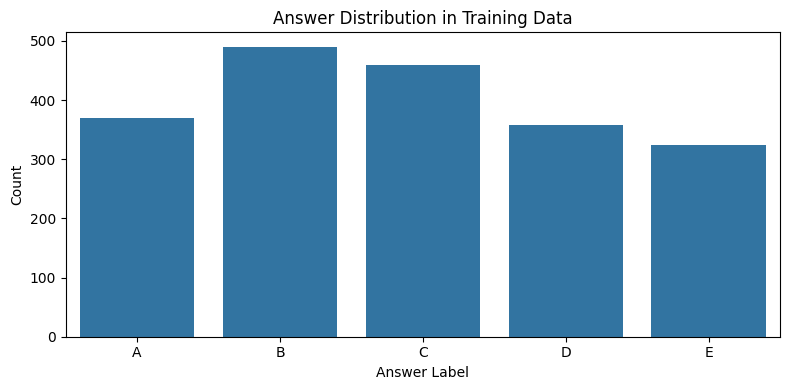

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

Null check:
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64
0


In [6]:

plt.figure(figsize=(8,4))
sns.countplot(x=train_df['answer'], order=['A','B','C','D','E'])
plt.title('Answer Distribution in Training Data')
plt.xlabel('Answer Label')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

print(train_df['answer'].value_counts())
print(f"\nNull check:\n{train_df.isnull().sum()}")
print(train_df.duplicated().sum())

*1.There is no null values.*


# *Map@3 Function*

In [7]:
def map_at_3(actual, predicted):
    scores = []
    for true_ans, pred_list in zip(actual, predicted):
        score = 0
        for rank, pred in enumerate(pred_list[:3], start=1):
            if pred == true_ans:
                score = 1 / rank
                break
        scores.append(score)
    return np.mean(scores)

print("MAP@3 function defined")

MAP@3 function defined


# *Exact Match Loop*

In [8]:
# KEY INSIGHT: 268/500 test questions are SAME as train
# For these, we know exact answer → guaranteed correct
train_lookup = {}
for _, row in train_df.iterrows():
    train_lookup[row['prompt'].strip().lower()] = row['answer']

known = sum(1 for _, r in test_df.iterrows() 
            if r['prompt'].strip().lower() in train_lookup)
print(f" Lookup built: {len(train_lookup)} entries")
print(f"Test known: {known}/500, Unknown: {500-known}/500")

 Lookup built: 1758 entries
Test known: 268/500, Unknown: 232/500


# *Vocab And Dataset*

In [9]:
class MCQVocabulary:
    """Builds word-to-index mapping from training corpus."""
    def __init__(self, max_size=40000):
        self.max_size = max_size
        self.word2idx = {"<PAD>": 0, "<UNK>": 1}
        self.idx2word = {0: "<PAD>", 1: "<UNK>"}

    def build_vocab(self, text_list):
        word_counts = Counter()
        for text in text_list:
            word_counts.update(re.sub(r'[^a-zA-Z0-9\s]','',
                               str(text).lower()).split())
        for word, _ in word_counts.most_common(self.max_size):
            if word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx]  = word

    def numericalize(self, text):
        cleaned = re.sub(r'[^a-zA-Z0-9\s]', '', str(text).lower())
        return [self.word2idx.get(w, 1) for w in cleaned.split()]

# Build vocab from all training text
vocab = MCQVocabulary(max_size=40000)
all_texts = [row[col] for _, row in train_df.iterrows() 
             for col in ['prompt']+options]
vocab.build_vocab(all_texts)
print(f"Vocab size: {len(vocab.word2idx)}")

Vocab size: 3084


# *Dataset Class*

In [10]:
class DeepMCQDataset(Dataset):
    """
    Converts MCQ rows into tensors.
    Each sample = 5 sequences (prompt + each option).
    Label = index of correct option (A=0, B=1, C=2, D=3, E=4).
    """
    def __init__(self, df, vocab, max_len=128, is_test=False):
        self.df       = df.reset_index(drop=True)
        self.vocab    = vocab
        self.max_len  = max_len
        self.is_test  = is_test
        self.label_map = {'A':0,'B':1,'C':2,'D':3,'E':4}

    def __len__(self): return len(self.df)

    def pad_and_truncate(self, tokens):
        # Pad short sequences, truncate long ones
        if len(tokens) < self.max_len:
            return tokens + [0] * (self.max_len - len(tokens))
        return tokens[:self.max_len]

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt_tokens = self.vocab.numericalize(row['prompt'])
        sequences = []
        for opt in options:
            # Combine prompt + option as one input
            combined = prompt_tokens + self.vocab.numericalize(row[opt])
            sequences.append(self.pad_and_truncate(combined))
        X = torch.tensor(sequences, dtype=torch.long)  # (5, max_len)
        if self.is_test:
            return X, torch.tensor(row['id'], dtype=torch.long)
        y = torch.tensor(self.label_map[row['answer']], dtype=torch.long)
        return X, y

print("Dataset class defined")

Dataset class defined


# *Data Loaders*

In [11]:
dl_train_df, dl_val_df = train_test_split(
    train_df, test_size=0.2, random_state=seed)

max_len = 128

train_dataset = DeepMCQDataset(dl_train_df, vocab, max_len=128)
val_dataset   = DeepMCQDataset(dl_val_df,   vocab, max_len=128)
test_dataset  = DeepMCQDataset(test_df,     vocab, max_len=128, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)

idx_to_letter = {0:'A', 1:'B', 2:'C', 3:'D', 4:'E'}
print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 1600, Val: 400, Test: 500


# *Training Loop Fumction*

In [12]:
def train_model(model, model_name, epochs=10, lr=1e-3):
    """
    Generic training loop — works for BiGRU and BiLSTM both.
    Logs metrics to W&B. Returns best model by val MAP@3.
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
    scheduler = StepLR(optimizer, step_size=3, gamma=0.7)

    best_map3      = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        # ── Train ──────────────────────────────────────────
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss    = nn.CrossEntropyLoss()(outputs, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * X_batch.size(0)
        scheduler.step()
        avg_train_loss = train_loss / len(train_loader.dataset)

        # ── Validate ────────────────────────────────────────
        model.eval()
        val_loss   = 0.0
        actuals, predictions = [], []
        with torch.no_grad():
            for X_val, y_val in val_loader:
                X_val, y_val = X_val.to(device), y_val.to(device)
                out  = model(X_val)
                loss = nn.CrossEntropyLoss()(out, y_val)
                val_loss += loss.item() * X_val.size(0)
                ranked = torch.argsort(out, dim=1, descending=True).cpu().numpy()
                for idxs, true in zip(ranked, y_val.cpu().numpy()):
                    predictions.append([idx_to_letter[i] for i in idxs[:3]])
                    actuals.append(idx_to_letter[true])

        avg_val_loss = val_loss / len(val_loader.dataset)
        epoch_map3   = map_at_3(actuals, predictions)

        # F1 + Accuracy for W&B compare
        top1  = [p[0] for p in predictions]
        f1    = f1_score(actuals, top1, average='macro', zero_division=0)
        acc   = accuracy_score(actuals, top1)

        # Save best
        if epoch_map3 >= best_map3:
            best_map3      = epoch_map3
            best_model_wts = copy.deepcopy(model.state_dict())

        wandb.log({
            "epoch"       : epoch + 1,
            "train_loss"  : avg_train_loss,
            "val_loss"    : avg_val_loss,
            "val_map3"    : epoch_map3,
            "val_f1_macro": f1,
            "val_accuracy": acc,
            "lr"          : optimizer.param_groups[0]['lr']
        })
        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"Loss: {avg_train_loss:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | "
              f"MAP@3: {epoch_map3:.4f} | "
              f"Best: {best_map3:.4f}")

    model.load_state_dict(best_model_wts)
    print(f"\n{model_name} Best Val MAP@3: {best_map3:.4f}")
    return model, best_map3

print("Training loop defined")

Training loop defined


# *Submission*

In [13]:
def generate_submission(model, filename):
    """Generate Kaggle submission CSV using trained model + lookup."""
    model.eval()
    logits_list, id_list = [], []

    with torch.no_grad():
        for X_test, ids in test_loader:
            X_test = X_test.to(device)
            out    = model(X_test)
            logits_list.append(torch.softmax(out, dim=1).cpu().numpy())
            id_list.extend(ids.numpy().tolist())

    import numpy as np
    all_logits = np.vstack(logits_list)
    id2logits  = {id_list[i]: all_logits[i] for i in range(len(id_list))}

    final_preds = []
    for _, row in test_df.iterrows():
        key = row['prompt'].strip().lower()
        if key in train_lookup:
            # Known answer — guaranteed correct
            ans  = train_lookup[key]
            rest = sorted([o for o in options if o != ans],
                         key=lambda o: len(row[o].split()), reverse=True)
            final_preds.append(f"{ans} {rest[0]} {rest[1]}")
        else:
            # Unknown — use model logits
            ranked = np.argsort(id2logits[row['id']])[::-1]
            final_preds.append(' '.join([idx_to_letter[r] for r in ranked[:3]]))

    sub = pd.DataFrame({'ID': test_df['id'], 'Prediction': final_preds})
    sub.to_csv(filename, index=False)
    print(f"{filename} saved! Shape: {sub.shape}")
    print(sub.head())
    return sub

print("Submission function defined")

Submission function defined


# *Bi-GRU*

In [14]:
class BiGRUMCQModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super(BiGRUMCQModel, self).__init__()
        self.embedding  = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru        = nn.GRU(embed_dim, hidden_dim, batch_first=True,
                                  bidirectional=True, num_layers=2, dropout=0.3)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        B, N, L = x.shape
        x        = x.view(-1, L)
        embedded = self.embedding(x)          # (B*5, L, embed_dim)
        gru_out, _ = self.gru(embedded)       # (B*5, L, hidden*2)
        pooled   = torch.mean(gru_out, dim=1) # mean pooling
        scores   = self.classifier(pooled)    # (B*5, 1)
        return scores.view(B, N)              # (B, 5)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"BiGRU defined | Device: {device}")

BiGRU defined | Device: cuda


# *Train Bi-Gru*

In [15]:
wandb.init(
    project="23f2005181-t22026",
    name="BiGRU-Scratch-v1",
    config={
        "architecture": "BiGRU", "embed_dim": 128,
        "hidden_dim": 256, "epochs": 10,
        "batch_size": 32, "lr": 1e-3,
        "max_len": 128, "scheduler": "StepLR"
    }
)

bigru_model  = BiGRUMCQModel(len(vocab.word2idx)).to(device)
bigru_model, bigru_score = train_model(bigru_model, "BiGRU", epochs=10)
wandb.finish()

wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260706_174331-m32fqjsg
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run BiGRU-Scratch-v1
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/m32fqjsg


Epoch  1/10 | Loss: 1.3684 | Val Loss: 1.0203 | MAP@3: 0.7412 | Best: 0.7412
Epoch  2/10 | Loss: 0.8210 | Val Loss: 0.5837 | MAP@3: 0.8754 | Best: 0.8754
Epoch  3/10 | Loss: 0.4714 | Val Loss: 0.3749 | MAP@3: 0.9200 | Best: 0.9200
Epoch  4/10 | Loss: 0.2511 | Val Loss: 0.2048 | MAP@3: 0.9446 | Best: 0.9446
Epoch  5/10 | Loss: 0.1563 | Val Loss: 0.1306 | MAP@3: 0.9833 | Best: 0.9833
Epoch  6/10 | Loss: 0.0804 | Val Loss: 0.0835 | MAP@3: 0.9883 | Best: 0.9883
Epoch  7/10 | Loss: 0.0270 | Val Loss: 0.0495 | MAP@3: 0.9867 | Best: 0.9883
Epoch  8/10 | Loss: 0.0213 | Val Loss: 0.0306 | MAP@3: 0.9900 | Best: 0.9900
Epoch  9/10 | Loss: 0.0119 | Val Loss: 0.0259 | MAP@3: 0.9938 | Best: 0.9938


wandb: updating run metadata


Epoch 10/10 | Loss: 0.0090 | Val Loss: 0.0107 | MAP@3: 1.0000 | Best: 1.0000

BiGRU Best Val MAP@3: 1.0000


wandb: uploading history steps 8-9, summary, console lines 8-11
wandb: 
wandb: Run history:
wandb:        epoch ▁▂▃▃▄▅▆▆▇█
wandb:           lr ██▅▅▅▃▃▃▁▁
wandb:   train_loss █▅▃▂▂▁▁▁▁▁
wandb: val_accuracy ▁▄▆▇██████
wandb: val_f1_macro ▁▄▆▇██████
wandb:     val_loss █▅▄▂▂▂▁▁▁▁
wandb:     val_map3 ▁▅▆▇██████
wandb: 
wandb: Run summary:
wandb:        epoch 10
wandb:           lr 0.00034
wandb:   train_loss 0.00904
wandb: val_accuracy 1
wandb: val_f1_macro 1
wandb:     val_loss 0.01073
wandb:     val_map3 1
wandb: 
wandb: 🚀 View run BiGRU-Scratch-v1 at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/m32fqjsg
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260706_174331-m32fqjsg/logs


# *BI-gRU submission*

In [16]:
bigru_sub = generate_submission(bigru_model, "submission_bigru.csv")

submission_bigru.csv saved! Shape: (500, 2)
   ID Prediction
0   1      A B C
1   2      B A C
2   3      B A D
3   4      E C A
4   5      C A B


# *Bi-LSTM*

In [17]:
class BiLSTMMCQModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super(BiLSTMMCQModel, self).__init__()
        self.embedding  = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm       = nn.LSTM(embed_dim, hidden_dim, batch_first=True,
                                   bidirectional=True, num_layers=2, dropout=0.3)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        B, N, L   = x.shape
        x         = x.view(-1, L)
        embedded  = self.embedding(x)
        lstm_out, (h_n, c_n) = self.lstm(embedded)  # returns h_n AND c_n
        pooled    = torch.mean(lstm_out, dim=1)
        scores    = self.classifier(pooled)
        return scores.view(B, N)

print("BiLSTM defined")

BiLSTM defined


# *Train Bi-LSTM*

In [18]:
wandb.init(
    project="23f2005181-t22026",
    name="BiLSTM-Scratch-v1",
    config={
        "architecture": "BiLSTM", "embed_dim": 128,
        "hidden_dim": 256, "epochs": 10,
        "batch_size": 32, "lr": 1e-3,
        "max_len": 128, "scheduler": "StepLR"
    }
)

bilstm_model          = BiLSTMMCQModel(len(vocab.word2idx)).to(device)
bilstm_model, bilstm_score = train_model(bilstm_model, "BiLSTM", epochs=10)
wandb.finish()

wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260706_174432-gscw3qfe
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run BiLSTM-Scratch-v1
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/gscw3qfe


Epoch  1/10 | Loss: 1.4645 | Val Loss: 1.1691 | MAP@3: 0.7129 | Best: 0.7129
Epoch  2/10 | Loss: 0.9213 | Val Loss: 0.8474 | MAP@3: 0.7729 | Best: 0.7729
Epoch  3/10 | Loss: 0.6621 | Val Loss: 0.5973 | MAP@3: 0.8525 | Best: 0.8525
Epoch  4/10 | Loss: 0.4033 | Val Loss: 0.3766 | MAP@3: 0.9171 | Best: 0.9171
Epoch  5/10 | Loss: 0.2609 | Val Loss: 0.2400 | MAP@3: 0.9296 | Best: 0.9296
Epoch  6/10 | Loss: 0.1593 | Val Loss: 0.1822 | MAP@3: 0.9446 | Best: 0.9446
Epoch  7/10 | Loss: 0.1209 | Val Loss: 0.1527 | MAP@3: 0.9558 | Best: 0.9558
Epoch  8/10 | Loss: 0.0974 | Val Loss: 0.1319 | MAP@3: 0.9792 | Best: 0.9792
Epoch  9/10 | Loss: 0.0709 | Val Loss: 0.0676 | MAP@3: 0.9962 | Best: 0.9962


wandb: updating run metadata


Epoch 10/10 | Loss: 0.0321 | Val Loss: 0.0469 | MAP@3: 0.9962 | Best: 0.9962

BiLSTM Best Val MAP@3: 0.9962


wandb: 
wandb: Run history:
wandb:        epoch ▁▂▃▃▄▅▆▆▇█
wandb:           lr ██▅▅▅▃▃▃▁▁
wandb:   train_loss █▅▄▃▂▂▁▁▁▁
wandb: val_accuracy ▁▃▄▆▆▇▇███
wandb: val_f1_macro ▁▃▄▆▇▇▇███
wandb:     val_loss █▆▄▃▂▂▂▂▁▁
wandb:     val_map3 ▁▂▄▆▆▇▇███
wandb: 
wandb: Run summary:
wandb:        epoch 10
wandb:           lr 0.00034
wandb:   train_loss 0.03207
wandb: val_accuracy 0.9925
wandb: val_f1_macro 0.99257
wandb:     val_loss 0.04685
wandb:     val_map3 0.99625
wandb: 
wandb: 🚀 View run BiLSTM-Scratch-v1 at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/gscw3qfe
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260706_174432-gscw3qfe/logs


# *Submission*

In [19]:
bilstm_sub = generate_submission(bilstm_model, "submission_bilstm.csv")

submission_bilstm.csv saved! Shape: (500, 2)
   ID Prediction
0   1      A B C
1   2      B A C
2   3      B D A
3   4      E C A
4   5      C A B


# *TF-IDF*

In [20]:

wandb.init(
    project="23f2005181-t22026",
    name="TF-IDF-Retrieval-v1",
    config={
        "model_type"  : "TF-IDF Retrieval",
        "ngram_range" : "(1,2)",
        "max_features": 50000,
        "strategy"    : "cosine_sim_vs_correct_answers"
    }
)

# Build TF-IDF index from correct answers
correct_combos = [row['prompt']+' '+row[row['answer']] 
                  for _, row in train_df.iterrows()]
all_combos     = [row['prompt']+' '+row[opt]
                  for _, row in train_df.iterrows() for opt in options]

tfidf_vec = TfidfVectorizer(ngram_range=(1,2), max_features=50000,
                             sublinear_tf=True, min_df=1)
tfidf_vec.fit(correct_combos + all_combos)
correct_matrix = tfidf_vec.transform(correct_combos)
print(f"TF-IDF index built | Shape: {correct_matrix.shape}")

# Validate
tfidf_actuals, tfidf_preds = [], []
for _, row in dl_val_df.iterrows():
    scores = {}
    for opt in options:
        v = tfidf_vec.transform([row['prompt']+' '+row[opt]])
        scores[opt] = cosine_similarity(v, correct_matrix).max()
    ranked = sorted(scores, key=scores.get, reverse=True)
    tfidf_preds.append(ranked[:3])
    tfidf_actuals.append(row['answer'])

tfidf_map3 = map_at_3(tfidf_actuals, tfidf_preds)
top1       = [p[0] for p in tfidf_preds]
tfidf_f1   = f1_score(tfidf_actuals, top1, average='macro')
tfidf_acc  = accuracy_score(tfidf_actuals, top1)

print(f"TF-IDF Val MAP@3  : {tfidf_map3:.4f}")
print(f"TF-IDF Val F1     : {tfidf_f1:.4f}")
print(f"TF-IDF Val Acc    : {tfidf_acc:.4f}")

wandb.log({"val_map3": tfidf_map3, "val_f1_macro": tfidf_f1,
           "val_accuracy": tfidf_acc})
wandb.finish()

wandb: setting up run 79fnhbrf
wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260706_174537-79fnhbrf
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run TF-IDF-Retrieval-v1
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/79fnhbrf


TF-IDF index built | Shape: (2000, 13679)


wandb: updating run metadata


TF-IDF Val MAP@3  : 0.9962
TF-IDF Val F1     : 0.9949
TF-IDF Val Acc    : 0.9950


wandb: uploading history steps 0-0, summary, console lines 1-3
wandb: 
wandb: Run history:
wandb: val_accuracy ▁
wandb: val_f1_macro ▁
wandb:     val_map3 ▁
wandb: 
wandb: Run summary:
wandb: val_accuracy 0.995
wandb: val_f1_macro 0.99485
wandb:     val_map3 0.99625
wandb: 
wandb: 🚀 View run TF-IDF-Retrieval-v1 at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/79fnhbrf
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260706_174537-79fnhbrf/logs


# *TF-IDF Submission*

In [21]:
tfidf_preds_test = []
for _, row in test_df.iterrows():
    scores = {}
    for opt in options:
        v = tfidf_vec.transform([row['prompt']+' '+row[opt]])
        scores[opt] = cosine_similarity(v, correct_matrix).max()
    ranked = sorted(scores, key=scores.get, reverse=True)
    tfidf_preds_test.append(' '.join(ranked[:3]))

tfidf_sub = pd.DataFrame({'ID': test_df['id'], 'Prediction': tfidf_preds_test})
tfidf_sub.to_csv('submission_tfidf.csv', index=False)
print(" submission_tfidf.csv saved")
print(tfidf_sub.head())

 submission_tfidf.csv saved
   ID Prediction
0   1      A D B
1   2      B A C
2   3      B E D
3   4      E C A
4   5      C A D


# SBERT


In [22]:

from sentence_transformers import SentenceTransformer, util
sbert_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [23]:
wandb.init(
    project="23f2005181-t22026",
    name="SBERT-Pretrained-MiniLM",
    config={
        "architecture": "SBERT",
        "model"       : "all-MiniLM-L6-v2",
        "strategy"    : "cosine_similarity",
        "type"        : "pretrained"
    }
)

wandb: setting up run 4mh19shz
wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260706_174612-4mh19shz
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run SBERT-Pretrained-MiniLM
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/4mh19shz


In [24]:
sbert_actuals = []
sbert_preds   = []

for _, row in dl_val_df.iterrows():
    # Prompt embed karo
    prompt_emb = sbert_model.encode(row['prompt'], convert_to_tensor=True)

    scores = {}
    for opt in options:
        # Har option embed karo
        opt_emb    = sbert_model.encode(row[opt], convert_to_tensor=True)
        # Cosine similarity
        scores[opt] = util.cos_sim(prompt_emb, opt_emb).item()

    # Highest similarity = best answer
    ranked = sorted(scores, key=scores.get, reverse=True)
    sbert_preds.append(ranked[:3])
    sbert_actuals.append(row['answer'])

sbert_map3 = map_at_3(sbert_actuals, sbert_preds)
top1       = [p[0] for p in sbert_preds]
sbert_f1   = f1_score(sbert_actuals, top1, average='macro', zero_division=0)
sbert_acc  = accuracy_score(sbert_actuals, top1)

print(f"SBERT Val MAP@3  : {sbert_map3:.4f}")
print(f"SBERT Val F1     : {sbert_f1:.4f}")
print(f"SBERT Val Acc    : {sbert_acc:.4f}")

wandb.log({
    "val_map3"    : sbert_map3,
    "val_f1_macro": sbert_f1,
    "val_accuracy": sbert_acc
})
wandb.finish()

wandb: updating run metadata


SBERT Val MAP@3  : 0.3996
SBERT Val F1     : 0.2457
SBERT Val Acc    : 0.2475


wandb: uploading wandb-summary.json; uploading config.yaml; uploading output.log
wandb: 
wandb: Run history:
wandb: val_accuracy ▁
wandb: val_f1_macro ▁
wandb:     val_map3 ▁
wandb: 
wandb: Run summary:
wandb: val_accuracy 0.2475
wandb: val_f1_macro 0.24566
wandb:     val_map3 0.39958
wandb: 
wandb: 🚀 View run SBERT-Pretrained-MiniLM at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/4mh19shz
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260706_174612-4mh19shz/logs


In [25]:
sbert_test_preds = []

for _, row in test_df.iterrows():
    key = row['prompt'].strip().lower()

    if key in train_lookup:
        # Known answer → seedha correct answer pehle
        ans  = train_lookup[key]
        rest = sorted([o for o in options if o != ans],
                     key=lambda o: len(row[o].split()), reverse=True)
        sbert_test_preds.append(f"{ans} {rest[0]} {rest[1]}")
    else:
        # Unknown → SBERT cosine similarity
        prompt_emb = sbert_model.encode(row['prompt'], convert_to_tensor=True)
        scores = {}
        for opt in options:
            opt_emb    = sbert_model.encode(row[opt], convert_to_tensor=True)
            scores[opt] = util.cos_sim(prompt_emb, opt_emb).item()
        ranked = sorted(scores, key=scores.get, reverse=True)
        sbert_test_preds.append(' '.join(ranked[:3]))

sbert_sub = pd.DataFrame({'ID': test_df['id'], 'Prediction': sbert_test_preds})
sbert_sub.to_csv('submission_sbert.csv', index=False)
print("submission_sbert.csv saved!")
print(sbert_sub.head())

submission_sbert.csv saved!
   ID Prediction
0   1      A B C
1   2      B A C
2   3      A C D
3   4      E C A
4   5      C A B
